# Fake News Detection - Classical Models

In [1]:
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# Folders for the dataset, figures and result tables
DATA_DIR = "../data/"
FIG_DIR = "../reports/figures/"
REPORT_DIR = "../reports/"

# Folder with preprocess.py
APP_DIR = "../app/"

# For Google Colab: uncomment these lines to use Google Drive instead
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/fake-news/data/"
# FIG_DIR = "/content/drive/MyDrive/fake-news/reports/figures/"
# REPORT_DIR = "/content/drive/MyDrive/fake-news/reports/"
# APP_DIR = "/content/drive/MyDrive/fake-news/app/"

# Create the output folders if they do not exist
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# Let Python find preprocess.py so the app and notebooks share the same cleaning
sys.path.append(APP_DIR)
from preprocess import clean_text

In [2]:
# Load the train and test splits from the first notebook
train_df = pd.read_csv(DATA_DIR + "train.csv")
test_df = pd.read_csv(DATA_DIR + "test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (50835, 2)
Test shape: (12709, 2)


In [3]:
# Two training articles before and after cleaning (first 300 characters)
for text in train_df["content"].head(2):
    print("Before:", text[:300])
    print("After: ", clean_text(text)[:300])
    print()

Before: Make music great again, with these 10 Trumped up album covers Next Swipe left/right Make music great again, with these 10 Trumped up album covers We’ve previously seen how the addition of Donald Trump can ruin perfectly good films , now the tiny-handed man baby ruins 10 albums. 1. — Suzanne McCusker
After:  make music great trumped album cover next swipe left right make music great trumped album cover previously seen addition donald trump ruin perfectly good film tiny handed man baby ruin album suzanne mccusker november

Before: Am I missing something here???? I take it to be saying that Sheriff Joe is ENFORCING the law?? And ENFORCING the law is criminal!!??!! Oh, I get it!....Just like the way Trump breaks the law when applying our TAX LAWS to his tax return!!???!! Hmmm, so now they squabble abt whether or not ENFORCING t
After:  missing something take saying sheriff joe enforcing law enforcing law criminal get like way trump break law applying tax law tax return hmmm squabbl

In [4]:
# Clean every article (this takes a few minutes)
train_df["clean"] = train_df["content"].apply(clean_text)
test_df["clean"] = test_df["content"].apply(clean_text)

In [5]:
# Save the cleaned splits so we don't have to clean again
train_df.to_csv(DATA_DIR + "train_clean.csv", index=False)
test_df.to_csv(DATA_DIR + "test_clean.csv", index=False)
print("Saved train_clean.csv and test_clean.csv")

Saved train_clean.csv and test_clean.csv


## Preprocessing steps

- **Tokenization:** the text is lowercased, URLs, HTML tags and non-letters are removed, and the rest is split into words on spaces.
- **Stopword removal:** common words like "the" and "is" are removed, but negations ("not", "no", "nor", and "don", "isn", "wasn" etc. because apostrophes were stripped) are kept, since they can flip the meaning.
- **Lemmatization vs stemming:** lemmatization turns words into real dictionary forms ("bills" -> "bill"), while stemming just chops endings and can give non-words ("studies" -> "studi").
- **Same function in the app:** `clean_text` lives in `app/preprocess.py`, so the Streamlit app cleans new text exactly like the training data; otherwise the model would see differently formatted input.

## TF-IDF Features

In [6]:
# Load the cleaned splits (so this section can run without cleaning again)
train_df = pd.read_csv(DATA_DIR + "train_clean.csv")
test_df = pd.read_csv(DATA_DIR + "test_clean.csv")

# Some articles are empty after cleaning (e.g. non-English text), so fill them with ""
X_train = train_df["clean"].fillna("")
X_test = test_df["clean"].fillna("")
y_train = train_df["is_fake"]
y_test = test_df["is_fake"]

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 50835
Test rows: 12709


In [7]:
# TF-IDF settings, reused by every model in this notebook
TFIDF_PARAMS = dict(
    ngram_range=(1, 2),   # use single words and pairs of words
    max_features=50000,   # keep the 50,000 most frequent terms
    min_df=3,             # ignore terms found in fewer than 3 articles
    max_df=0.9,           # ignore terms found in more than 90% of articles
    sublinear_tf=True,    # use 1 + log(count) so repeated words don't dominate
)

In [8]:
vec = TfidfVectorizer(**TFIDF_PARAMS)

# Learn the vocabulary from the training data only.
# Fitting on test data would leak information about the test set into the model.
X_train_tfidf = vec.fit_transform(X_train)
X_test_tfidf = vec.transform(X_test)

print("Train matrix shape:", X_train_tfidf.shape)
print("Test matrix shape:", X_test_tfidf.shape)

Train matrix shape: (50835, 50000)
Test matrix shape: (12709, 50000)


In [9]:
feature_names = pd.Series(vec.get_feature_names_out())
print("Vocabulary size:", len(feature_names))

# 10 random single words and 10 random word pairs
is_bigram = feature_names.str.contains(" ")
print("\nUnigrams:", list(feature_names[~is_bigram].sample(10, random_state=42)))
print("Bigrams:", list(feature_names[is_bigram].sample(10, random_state=42)))

Vocabulary size: 50000

Unigrams: ['valid', 'outlining', 'visiting', 'selling', 'forcing', 'exhaust', 'fulfill', 'honed', 'craig', 'pope']
Bigrams: ['moment history', 'trump face', 'gov mike', 'also voted', 'state group', 'lavoy finicum', 'stood behind', 'water cannon', 'friday called', 'still struggling']


## How TF-IDF works

- **TF (term frequency):** how often a word appears in one article; here we use 1 + log(count) so a word used 50 times doesn't count 50 times more.
- **IDF (inverse document frequency):** how rare a word is across all articles; words found in almost every article get a low weight.
- **TF x IDF:** a word gets a high score when it is common in this article but rare overall, so the distinctive words of each article stand out.
- **Sparse matrix:** each article uses only a few hundred of the 50,000 terms, so most values are 0 and only the non-zero values are stored.

## Model Training

In [10]:
# The four classical models we compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
}

/Users/vaishnavi/Desktop/Fake News Detection/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


In [11]:
train_times = {}  # training time in seconds for each model
trained = {}      # fitted models

for name, model in models.items():
    start = time.time()
    model.fit(X_train_tfidf, y_train)
    train_times[name] = round(time.time() - start, 2)
    trained[name] = model
    print(f"{name}: {train_times[name]} seconds")

Logistic Regression: 0.79 seconds
Naive Bayes: 0.02 seconds
Passive Aggressive: 0.48 seconds
Linear SVM: 1.34 seconds


In [12]:
# Quick check: accuracy on the test set
for name, model in trained.items():
    y_pred = model.predict(X_test_tfidf)
    print(f"{name}: {accuracy_score(y_test, y_pred):.4f}")

Logistic Regression: 0.9467
Naive Bayes: 0.8647
Passive Aggressive: 0.9532
Linear SVM: 0.9574


## How each model decides

- **Logistic Regression:** gives each word a weight, adds them up, and turns the total into a fake probability with the sigmoid function.
- **Naive Bayes:** uses Bayes' theorem to pick the more likely class, assuming each word appears independently of the others.
- **Passive Aggressive:** updates its weights only when it makes a mistake, so it can keep learning from a stream of new articles.
- **Linear SVM:** finds the line (hyperplane) that separates real and fake articles with the widest possible margin.

## Evaluation

In [13]:
rows = []
predictions = {}  # test predictions of each model, reused below

for name, model in trained.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    # ROC-AUC needs scores: probabilities if the model has them, otherwise decision scores
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_test_tfidf)

    # Precision, recall and F1 treat fake (1) as the positive class
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Train time (s)": train_times[name],
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False).round(4)
results.to_csv(REPORT_DIR + "results_classical.csv")
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
Model,,,,,,
Linear SVM,0.9574,0.9535,0.9522,0.9528,0.9922,1.34
Passive Aggressive,0.9532,0.9491,0.9473,0.9482,0.9913,0.48
Logistic Regression,0.9467,0.9421,0.9400,0.9411,0.9879,0.79
Naive Bayes,0.8647,0.8316,0.8792,0.8547,0.9387,0.02


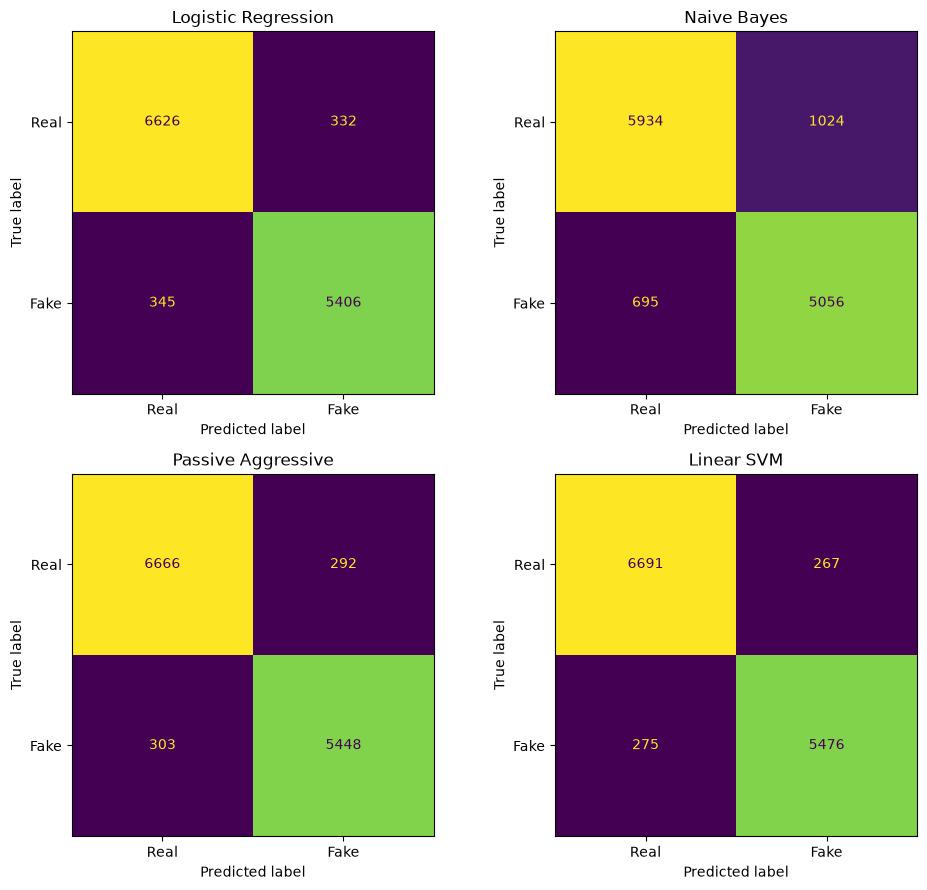

In [14]:
# Confusion matrix for each model
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Real", "Fake"], colorbar=False, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(FIG_DIR + "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

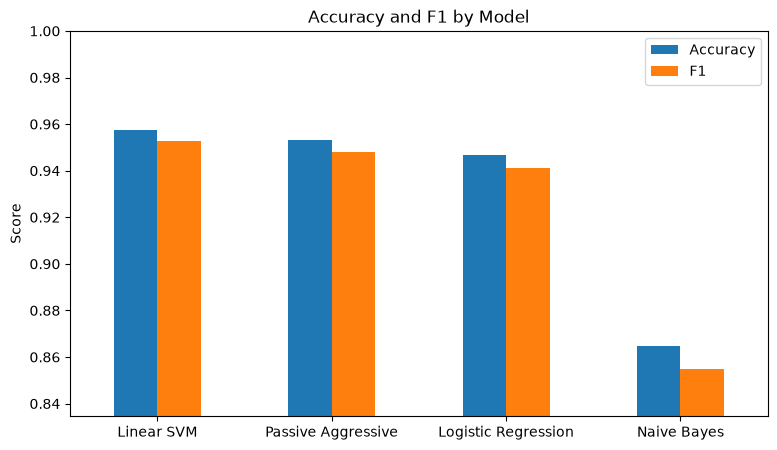

In [15]:
# Accuracy and F1 side by side for each model
scores = results[["Accuracy", "F1"]]
ax = scores.plot(kind="bar", figsize=(9, 5), rot=0)

# Start the y-axis just below the lowest score so differences are visible
ax.set_ylim(scores.min().min() - 0.02, 1.0)
ax.set_title("Accuracy and F1 by Model")
ax.set_xlabel("")
ax.set_ylabel("Score")

plt.savefig(FIG_DIR + "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Best model = highest F1 (first row of the sorted results)
best_name = results.index[0]
print("Best model by F1:", best_name)

# Table of true vs predicted labels for every test article
labels = {0: "Real", 1: "Fake"}
errors = pd.DataFrame({
    "content": test_df["content"].str[:300],
    "true": y_test.map(labels),
    "predicted": pd.Series(predictions[best_name], index=test_df.index).map(labels),
})

# Keep only the articles the model got wrong
errors = errors[errors["true"] != errors["predicted"]]

print("False positives (real flagged as fake):", (errors["true"] == "Real").sum())
print("False negatives (fake missed as real):", (errors["true"] == "Fake").sum())

# Show the full 300 characters instead of cutting them short
pd.set_option("display.max_colwidth", 300)
errors.head(5)

Best model by F1: Linear SVM
False positives (real flagged as fake): 267
False negatives (fake missed as real): 275


,content,true,predicted
1,"Sweden Launches Program to Stem Surge in Anti-Semitism and Holocaust Denial The Jerusalem Post reports: With surveys showing “lots of Swedish Jews are afraid of showing their Jewishness,” Stockholm has stepped up efforts to teach about the Holocaust as a means of fighting against antisemitism, t...",Real,Fake
12,"Trump: I’d Get ‘Electric Chair’ for Cheating on Debates Like Hillary Posted 10/31/2016 2:03 pm by PatriotRising with 0 comments Republican nominee Donald Trump told an audience of roughly 8,000 cheering fans that if he had cheated in presidential debates the way rival Hillary Clinton had, he wou...",Fake,Real
19,"Crickets, Snakes, Crabs: A Mix of Fact and Fraud in New York’s Subway Perhaps you’ve heard the saying, “You can’t make this stuff up. ” So, so wrong. It turns out the subway cricket lady was a prank. The subway riders? Flimflam. Even, it seems, that New Yorker the Pizza Rat may have been schoole...",Real,Fake
24,"We must call him a terrorist: Dylann Roof, Fox News and the truth about why language matters Language can obscure as much as it reveals. It’s important, now more than ever, to be clear, to call things by their proper name; to do otherwise is to risk confusion where none exists. What happened in ...",Real,Fake
34,Oregon Standoff Acquittal Sparks Fears of New Land Disputes Oregon Standoff Acquittal Sparks Fears of New Land Disputes 11/01/2016 AGWEB The stunning acquittal of seven people who occupied a federal wildlife sanctuary in Oregon during an armed standoff raised fears Friday that the verdict could ...,Fake,Real


## Why these were wrong

- 
- 
- 

## Metrics explained

- **Precision:** of the articles the model flagged as fake, how many really were fake.
- **Recall:** of all the fake articles, how many the model caught.
- **F1 (main metric):** the balance of precision and recall in one number, so a model can't look good by being strong at only one of them.
- **Which error is worse:** a false negative (fake news missed) lets misinformation spread, which is usually worse; a false positive (real news flagged) hurts trust in the tool, so both matter.